Shape Recovery from Real Data

# Headers

In [28]:
import copy
import types
from ipywidgets import interact, widgets
import os
workspace_path = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))

import sys
sys.path.append(workspace_path)

import lib.constants as constants
from lib.utils_real import *
from lib.optimization import *

In [29]:
filename = 'real_data_opti-v3-v4'
experiments_file = 'real_experiments_log'

In [30]:
if torch.cuda.is_available():
    device = torch.device("cuda:0")
    torch.set_default_tensor_type(torch.cuda.FloatTensor)
else:
    device = torch.device("cpu")

# Macros

In [31]:
params_dict = {
    'optimize_MinvL': 1,

    'max_img_size': (192, 240),
    'start_img_size': (192, 240),
    # 'start_img_size': (64, 80),

    'NUM_BG_FRAMES': 1,
    'NUM_FRAME_DELTA': 1,
    'obj_dist': 0.4445, #0.3683,
    'zfar': 0.4845, #0.4762, #0.40,
    'znear': 0.4045, #0.4128, #0.3366,
    'limit_zvals': 0,

    'add_origverts_to_initmesh': 1,
    'ADD_RADIATION': 1,
    'ADD_CONVECTION': 1,

    # Things to optimize for?
    'optim_laplacian': 1,
    'optim_shape': 1,
    'optim_heat_vals': 1,
    'optim_heat_vals_all_vertices': 1,
    'optim_heat_source': 1,
    'optim_scale_factor': 0,
    'optim_thermal_diff': 0,
    'optim_heat_capacity': 1,
    'optim_convection_coeff': 1,
    'optim_thermal_cond' : 0,
    
    # 'use_shading_constraint': 1,
    'light_directions': [[50.0, 0.0, 50.0]],

    'use_image_symmetry_constraint': 1,
    'symmetric_about_axis': 1,

    'init_mesh_from_mask': 1,
    'unproject_and_update': 1,
    'num_views': 1,
    'SURFACE_THICKNESS': 3e-6, #0.0003,  # mm,
    'obj_material': 'polystyrene',
    'obj_name': 'bear',
    'num_files': 1,
    'device': device,
    'filename' : filename,
    
    # Add try
    'split_final_stage_opti': 1,
}

params = types.SimpleNamespace(**params_dict)
constants.set_focus_distance(params.obj_dist * 1000.0)

FOCUS_DISTANCE set:  444.5


# Load Video

In [32]:
# video_filename = "bear-v34-0-left-rad1-tlin0-2023-10-16_13-14-39.npz"
# video_filename = "bear-v34-1-right-rad1-tlin0-2023-10-16_13-07-11.npz"

# ## Bear
# video_filenames = ["bear-v34-0-left-rad1-tlin0-2023-10-16_13-14-39.npz",
#                 #    "bear-v34-1-right-rad1-tlin0-2023-10-16_13-07-11.npz"
#                    ]

## Bunny
# video_filenames = ["bunny-black-v81-incan-0-left-rad1-tlin0-2024-01-28_17-19-43.npz",
#                 #    "bunny-black-v81-incan-1-right-rad1-tlin0-2024-01-28_17-20-53.npz"
#                    ]
video_filenames = ["bunny-black-v81-incan-0-left-rad1-tlin0-2024-01-28_17-19-43.npz"]


# # Sphere
# video_filenames = ["sphere-v32-0-left-rad1-tlin0-2023-10-13_13-15-54.npz",
#                 #    "sphere-v32-1-right-rad1-tlin0-2023-10-13_13-18-47.npz"
#                    ]

# ## Soda-can
# video_filenames = ["soda_can-v43-0-left-incan-rad1-tlin0-2023-10-21_18-47-43.npz",
#                    "soda_can-v43-1-right-incan-rad1-tlin0-2023-10-21_18-50-52.npz"
#                    ]

# ## Plastic-Bottle (Not good)
# video_filenames = ["plastic-bottle-v2-v50-0-heatlamp-upleft-rad1-tlin0-2023-10-26_23-55-35.npz",
#                    "plastic-bottle-v2-v50-1-heatlamp-bottomright-rad1-tlin0-2023-10-26_23-57-23.npz"]

## Sleeping-face (Not good)
# video_filenames = ["sleepingface-v105-heatgun-2-topleft-rad1-tlin0-2024-09-11_11-34-05.npz",
#                    "sleepingface-v105-heatgun-1-bottomright-rad1-tlin0-2024-09-11_11-20-42.npz",
#                    "sleepingface-v105-heatgun-0-bottomleft-rad1-tlin0-2024-09-11_10-55-47.npz"
#                    ]

## Facepalm (Not good)
# video_filenames = ["facepalm-v104-heatgun-3-bottomleft-rad1-tlin0-2024-09-10_17-18-08.npz",
#                    "facepalm-v104-heatgun-0-topleft-rad1-tlin0-2024-09-09_12-02-01.npz",
#                    "facepalm-v104-heatgun-1-bottomright-rad1-tlin0-2024-09-09_12-12-24.npz",
#                    "facepalm-v104-heatgun-2-topright-rad1-tlin0-2024-09-10_17-07-24.npz",
#                    ]

# # Textured-glass (Not good)
# video_filenames = ["texturedglass-v103-heatgun-0-topleft-rad1-tlin0-2024-09-09_11-14-57.npz",
#                    "texturedglass-v103-heatgun-2-bottomright-rad1-tlin0-2024-09-09_11-40-30.npz"]


# video_filenames = ["thermal_video_20251218_162529_30fps-droplet-stronglight.npz"]
# video_filenames = ["thermal_video_20251219_190720_30fps_droplet-stronglight.npz"]

# # Heart
# video_filenames = ["thermal_video_20251231_153423_10fps_heart-stronglight.npz"]

# Painted-bear
# video_filenames = ["thermal_video_20260108_170144_10fps_paintedbear-stronglight.npz"]

views_azim_angles = [0]
views_elev_angles = [0]

# Set light directions
ps_gt = params.light_directions[0][0] / params.light_directions[0][2]
qs_gt = params.light_directions[0][1] / params.light_directions[0][2]

params.num_files = len(video_filenames)
params.obj_name = video_filenames[0].split('-')[0]
# params.light_directions = [[-0.1439466386421813, -0.44995416229615315, 0.8813742775098354]]

# Marcos
params.K = constants.TDiff[params.obj_material]
params.RHO = constants.Density[params.obj_material]
params.C = constants.SpecificHeat[params.obj_material]
params.ABS = constants.Absorptivity[params.obj_material]

## Read Frames

In [33]:
frame_recording = []
bg_recording = []
for video_filename in tqdm(video_filenames):
    if params.optimize_MinvL:
        data = np.load(os.path.join(workspace_path, 'DATA', 'obj_study_raw', video_filename), allow_pickle=True)
        recording = data["frame_recording"]
        # recording = data["frames"]
        if len(recording.shape) == 3:
            recording = recording[np.newaxis]
        del data
        frame_recording.append(recording[0, params.NUM_BG_FRAMES+10::params.NUM_FRAME_DELTA])
        bg_recording.append(recording[0, params.NUM_BG_FRAMES: params.NUM_BG_FRAMES+10])
        print(frame_recording[-1].shape)
        del recording
    else:
        frame_recording.append(np.zeros((1,512,640)))
        bg_recording.append(np.zeros((10,512,640)))
    
min_frames = min([x.shape[0] for x in frame_recording])
frame_recording = [x[:min_frames] for x in frame_recording]
frame_recording = np.array(frame_recording)
bg_recording = np.array(bg_recording)

100%|██████████| 1/1 [00:00<00:00,  6.36it/s]

(937, 512, 640)


# Load Mask

Loading mask from /path/to/shape-from-heat-conduction-and-shading/DATA/obj_study_proc/bunny-black-v81-incan-0-left-rad1-tlin0-2024-01-28_17-19-43_mask.pkl
Loaded mask with mean 0.0 and stdrange = 4.55


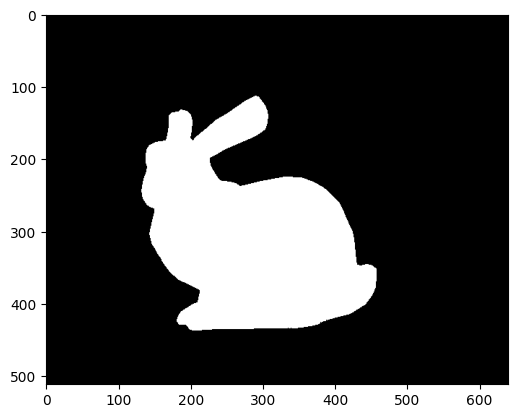

In [34]:
frame_mask = []
mask_filename = video_filename.split('.')[0] + '_mask.png'
mask_filepath = os.path.join(workspace_path, 'DATA', 'obj_study_proc', mask_filename)
png_file = True

# Check if mask file exists
if not os.path.exists(mask_filepath):
    mask_filename = video_filename.split('.')[0] + '_mask.pkl'
    mask_filepath = os.path.join(workspace_path, 'DATA', 'obj_study_proc', mask_filename)
    png_file = False
try:
    if not png_file:
        print('Loading mask from {}'.format(mask_filepath))
        with open(mask_filepath, 'rb') as f:
            mask_dict = pkl.load(f)
            frame_mask.append(mask_dict['mask'])
            print('Loaded mask with mean {} and stdrange = {}'.format(mask_dict['mean'], mask_dict['stdrange']))
            del mask_dict
    else:
        mask = cv2.imread(mask_filepath, 0)/255.0
        mask = mask.astype(int)
        frame_mask.append(mask)
except Exception as e:
    print(e)

frame_mask = np.array(frame_mask)
combined_mask = np.any(frame_mask, axis=0)
plt.imshow(combined_mask, cmap='gray')
plt.show()
view_masks_forobj = np.stack(frame_mask, axis=0).astype(int)
view_masks_forobj_pt = torch.tensor(view_masks_forobj).float().to(device)

# Preprocessing

## Visualize Contormap

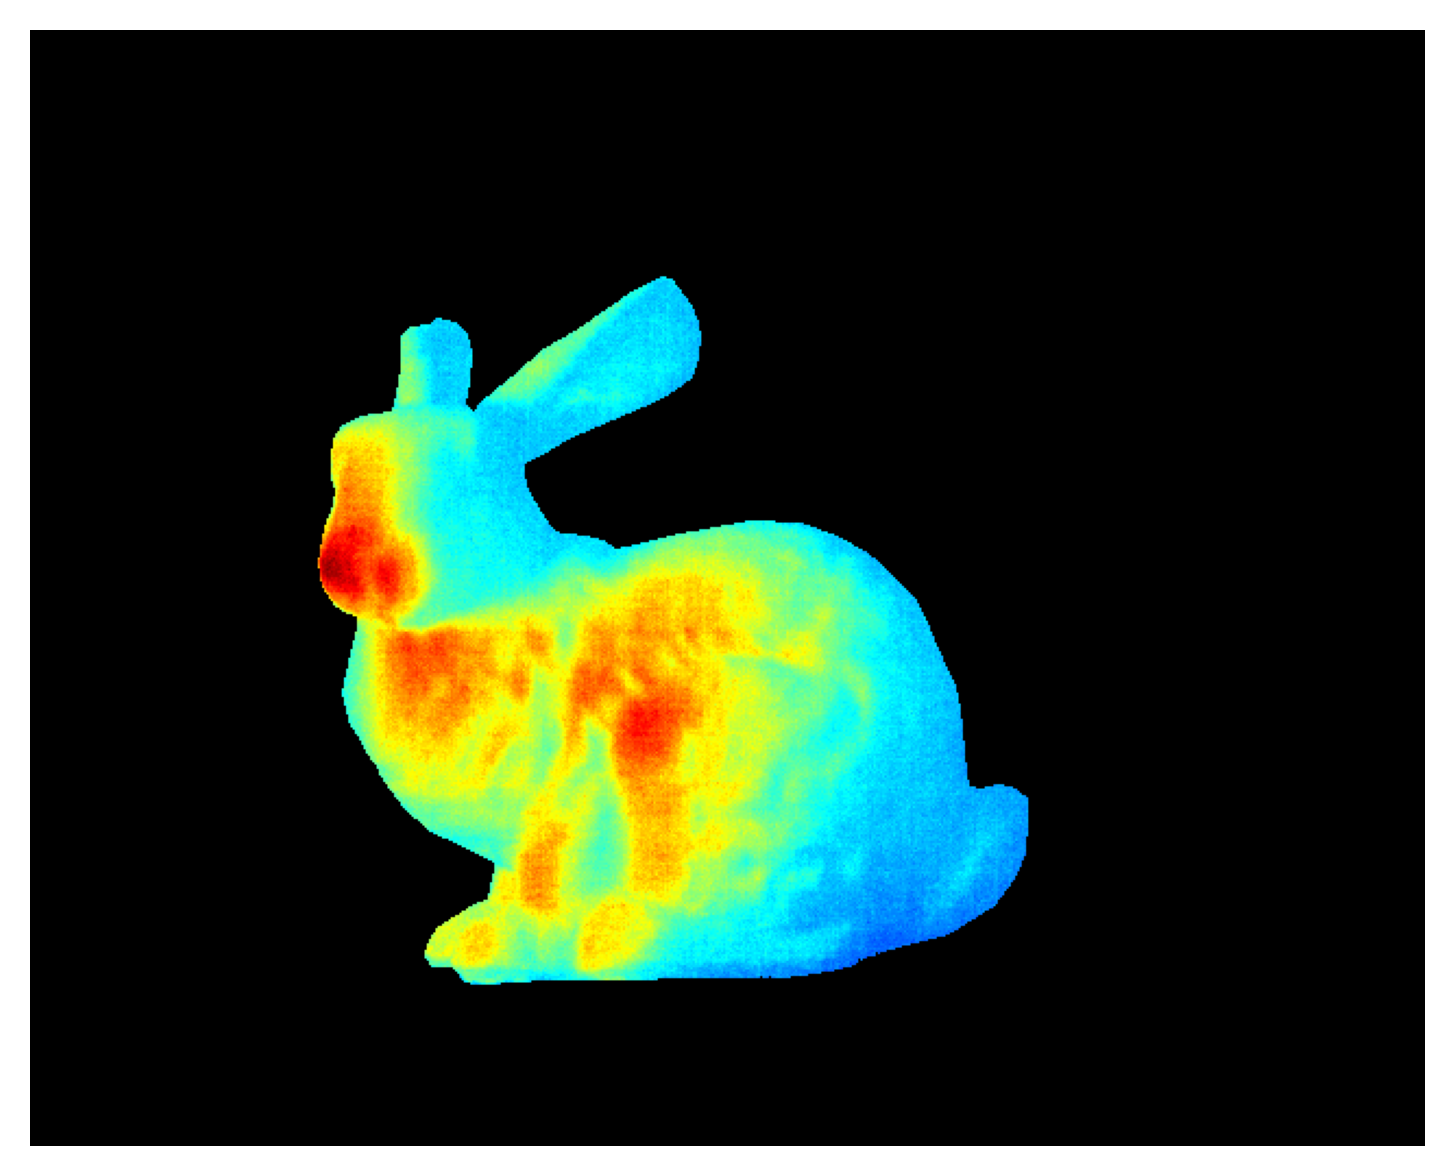

In [35]:
import skimage as sk
frame_no = 30
video_num = 0

for frame_no in [30]:
    # frame_min = frame_recording[0][-1].min()
    # frame_max = frame_recording[0][-1].max()
    frame_min = frame_recording[0][frame_no].min()
    frame_max = frame_recording[0][frame_no].max()
    frame_dis = 255*(frame_recording[0][frame_no].astype(float) - frame_min)/(frame_max - frame_min)

    frame_dis = cv2.applyColorMap(frame_dis.astype(np.uint8), cv2.COLORMAP_JET)

    fig_name = video_filenames[video_num].split('.')[0] + f'_{frame_no}-v1.png'
    img_path = os.path.join(workspace_path, 'results', 'paper_figs', fig_name)
    # sk.io.imsave(img_path, frame_dis.astype(np.uint8)[:, :, ::-1])

    frame_dis[~combined_mask] = 0.0
    fig_name = video_filenames[video_num].split('.')[0] + f'_{frame_no}-v2.png'
    img_path = os.path.join(workspace_path, 'results', 'paper_figs', fig_name)
    # sk.io.imsave(img_path, frame_dis.astype(np.uint8)[:, :, ::-1])

    # VIS
    plt.figure(figsize=(6, 6), dpi=300)
    plt.imshow(frame_dis.astype(np.uint8)[:, :, ::-1])
    plt.axis('off')
    plt.show()

In [36]:
print(f"Processing {filename}")
print(f"Saving video... {os.path.join(workspace_path, 'DATA', 'obj_study_videos',video_filenames[video_num].split('.')[0])}")
fourcc = cv2.VideoWriter_fourcc(*'mp4v')

video_writer_normal = cv2.VideoWriter(os.path.join(workspace_path, 'DATA', 'obj_study_videos',
                        f"{video_filenames[video_num].split('.')[0]}-{params.obj_name}-nobg.mp4"),
                        fourcc,
                        60,
                        (frame_recording.shape[-1], frame_recording.shape[-2]))

video_writer_black = cv2.VideoWriter(os.path.join(workspace_path, 'DATA', 'obj_study_videos',
                        f"{video_filenames[video_num].split('.')[0]}-{params.obj_name}-blackbg.mp4"),
                        fourcc,
                        60,
                        (frame_recording.shape[-1], frame_recording.shape[-2]))

video_writer_white = cv2.VideoWriter(os.path.join(workspace_path, 'DATA', 'obj_study_videos',
                        f"{video_filenames[video_num].split('.')[0]}-{params.obj_name}-whitebg.mp4"),
                        fourcc,
                        60,
                        (frame_recording.shape[-1], frame_recording.shape[-2]))

print(frame_recording.shape)
frame_min = frame_recording[0][:].min()
frame_max = frame_recording[0][:].max()
    
for frame_no in range(frame_recording[0].shape[0]):

    frame_dis = 255*(frame_recording[0][frame_no].astype(float) - frame_min)/(frame_max - frame_min)
    frame_dis = cv2.applyColorMap(frame_dis.astype(np.uint8), cv2.COLORMAP_JET)
    video_writer_normal.write(frame_dis.astype(np.uint8))

    frame_dis_black = frame_dis.copy()
    frame_dis_black[~combined_mask] = 0.0
    video_writer_black.write(frame_dis_black.astype(np.uint8))

    frame_dis_white = frame_dis.copy()
    frame_dis_white[~combined_mask] = 255
    video_writer_white.write(frame_dis_white.astype(np.uint8))
    
video_writer_normal.release()
video_writer_black.release()
video_writer_white.release()

Processing real_data_opti-v3-v4
Saving video... /path/to/shape-from-heat-conduction-and-shading/DATA/obj_study_videos/bunny-black-v81-incan-0-left-rad1-tlin0-2024-01-28_17-19-43
(1, 937, 512, 640)


In [37]:
print(f"Processing {filename}")
print(f"Saving video... {os.path.join(workspace_path, 'DATA', 'obj_study_videos',video_filenames[video_num].split('.')[0])}")
fourcc = cv2.VideoWriter_fourcc(*'mp4v')

video_writer_contour = cv2.VideoWriter(os.path.join(workspace_path, 'DATA', 'obj_study_videos',
                        f"{video_filenames[video_num].split('.')[0]}-{params.obj_name}-contour.mp4"), 
                        fourcc,
                        60, 
                        (frame_recording.shape[-1], frame_recording.shape[-2]))

video_writer_contour_white = cv2.VideoWriter(os.path.join(workspace_path, 'DATA', 'obj_study_videos',
                        f"{video_filenames[video_num].split('.')[0]}-{params.obj_name}-contour-whitebg.mp4"), 
                        fourcc,
                        60, 
                        (frame_recording.shape[-1], frame_recording.shape[-2]))

print(frame_recording.shape)
cmin = frame_recording[0][:10].min()
cmax = int(cmin + (frame_recording[0][:10].max() - cmin)*0.5)

for frame_no in range(100,frame_recording[0].shape[0]):
    frame_min = frame_recording[0][frame_no].min()
    frame_max = frame_recording[0][frame_no].max()

    frame_contour = 255*(frame_recording[0][frame_no].astype(float) - cmin)/(cmax - cmin)
    frame_contour = cv2.applyColorMap(frame_contour.astype(np.uint8), cv2.COLORMAP_JET)

    frame_contour_black = frame_contour.copy()
    frame_contour_black[~combined_mask] = 0
    video_writer_contour.write(frame_contour_black.astype(np.uint8))

    frame_contour_white = frame_contour.copy()
    frame_contour_white[~combined_mask] = 255
    video_writer_contour_white.write(frame_contour_white.astype(np.uint8))

video_writer_contour.release()
video_writer_contour_white.release()

Processing real_data_opti-v3-v4
Saving video... /path/to/shape-from-heat-conduction-and-shading/DATA/obj_study_videos/bunny-black-v81-incan-0-left-rad1-tlin0-2024-01-28_17-19-43
(1, 937, 512, 640)


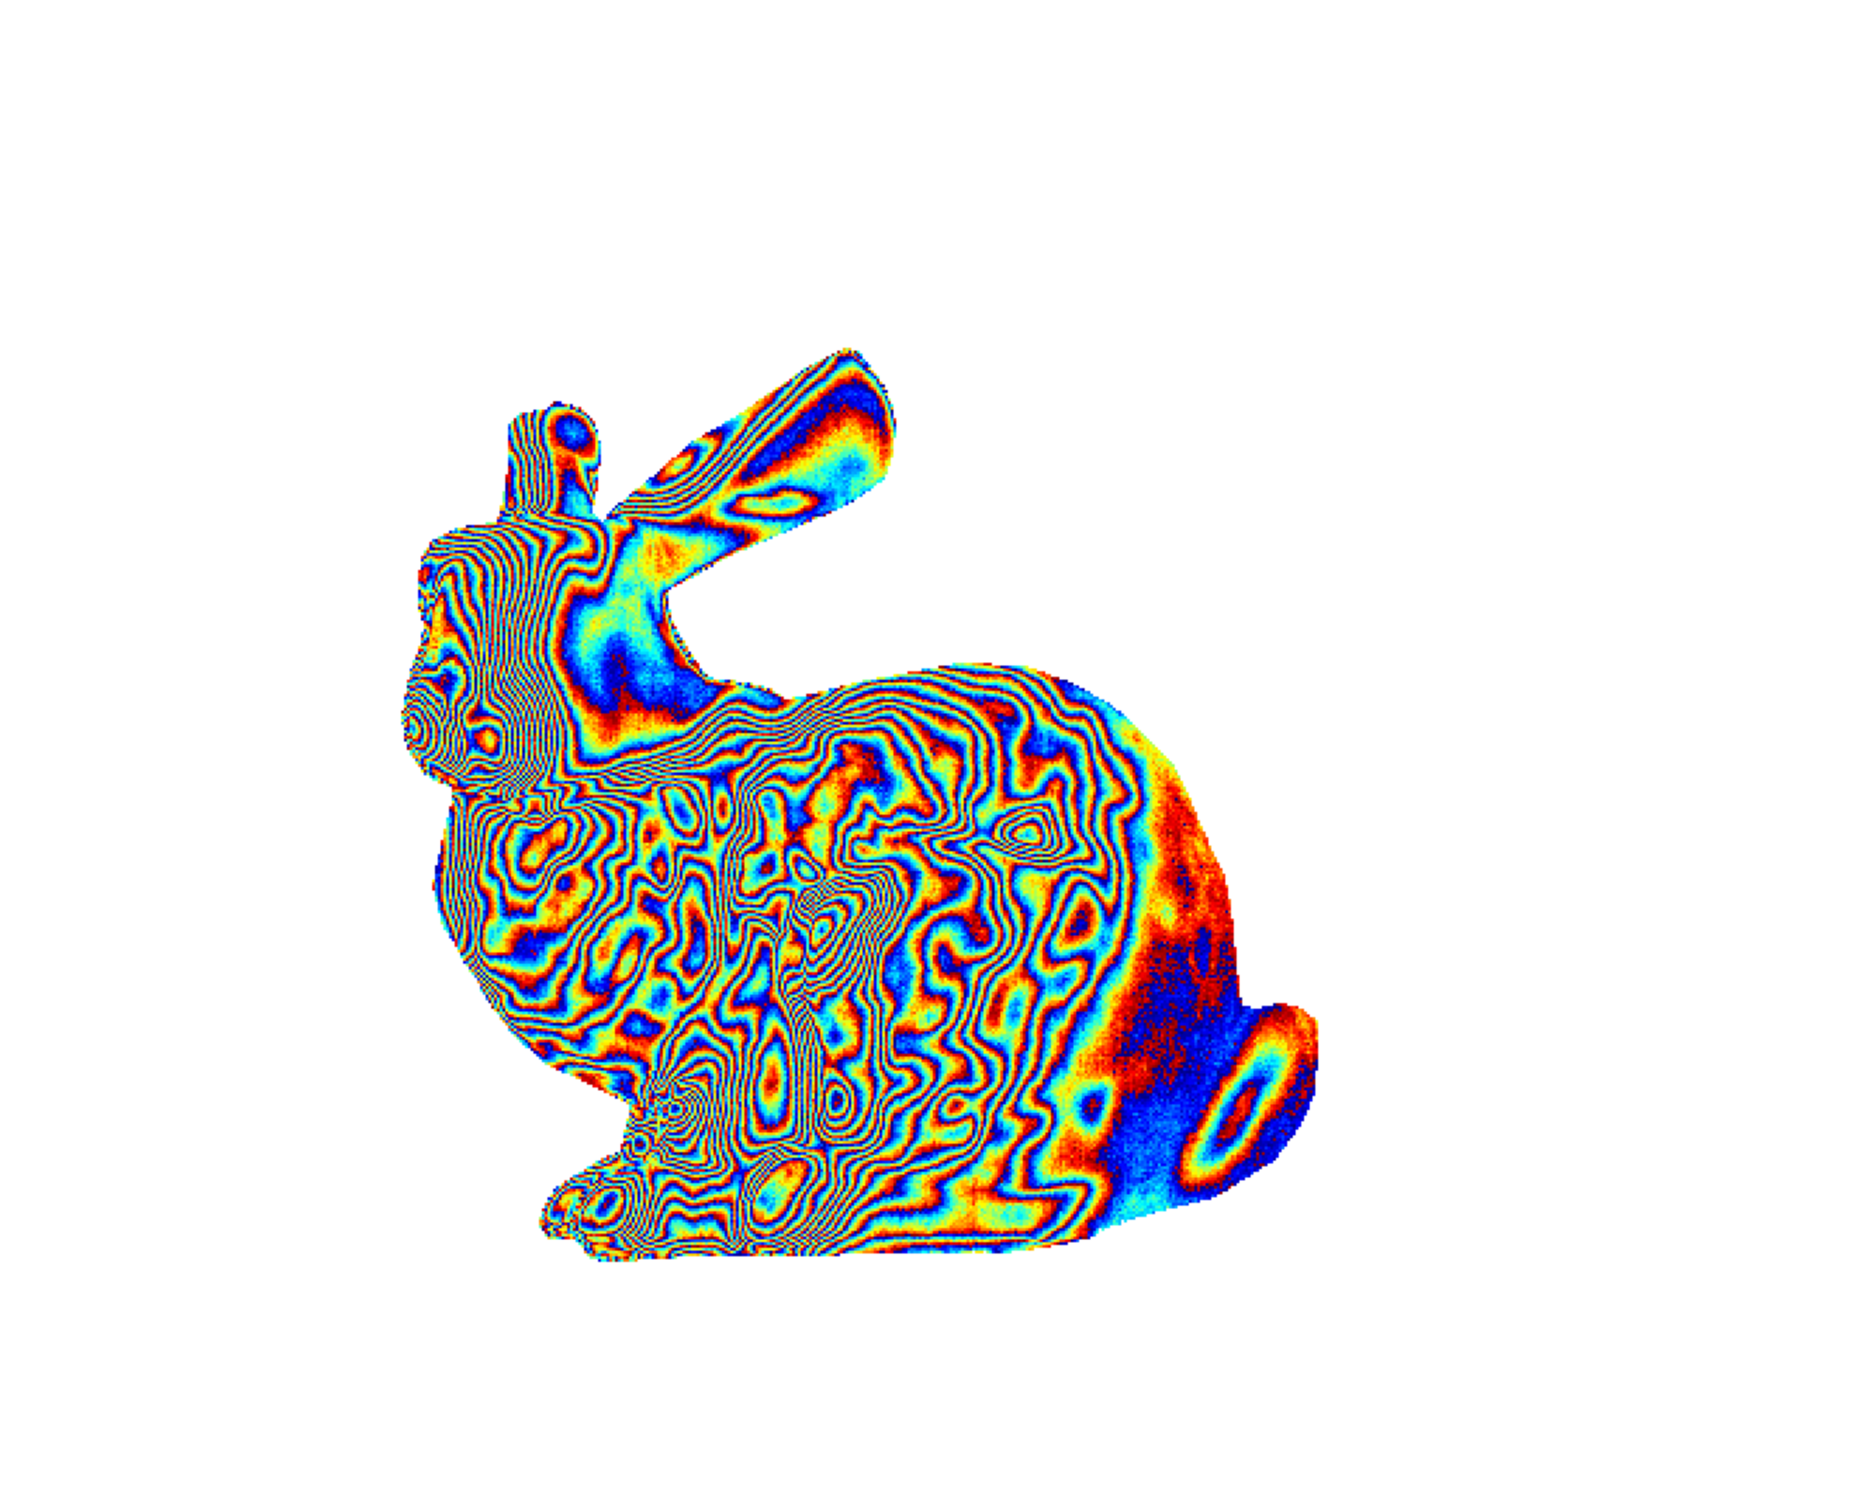

In [38]:
frame_no = 20

frame_contour_white = frame_contour.copy()
frame_contour_white[~combined_mask] = 255

save_path = os.path.join(workspace_path,
                        'DATA',
                        'obj_study_figs',
                        f"{params.obj_name}-contour-frame{frame_no:04d}.png")

# Plot
plt.figure(figsize=(6, 6), dpi=300)
plt.imshow(frame_contour_white)
plt.axis("off")
plt.tight_layout(pad=0)

# Save
plt.savefig(save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0)

plt.show()
plt.close()